1. Charger les données (S&P 500 et USREC)

S&P 500 : (2513, 1) | du 2016-11-07 au 2026-11-05
                    SP500
observation_date         
2016-11-07        2131.52
2016-11-08        2139.56
2016-11-09        2163.26
2016-11-10        2167.48
2016-11-11        2164.45 

USREC : (2063, 1)
                  USREC
observation_date       
2019-12-01            0
2020-01-01            0
2020-02-01            0
2020-03-01            1
2020-04-01            1
2020-05-01            0
2020-06-01            0
2020-07-01            0
2020-08-01            0


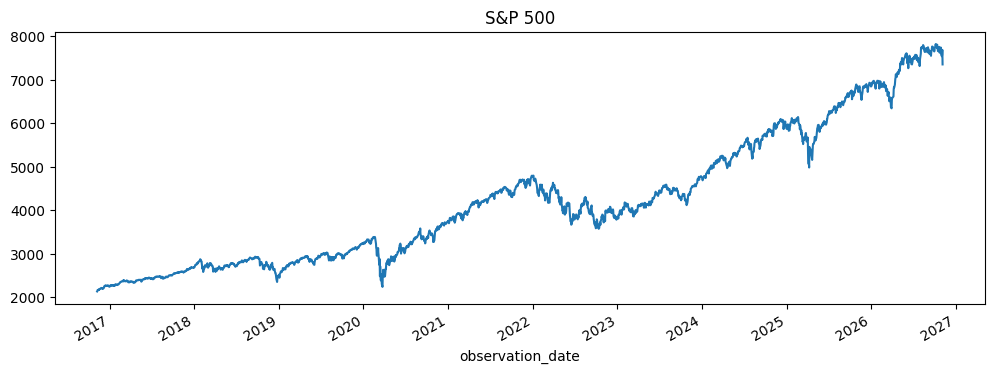

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. S&P 500 (prix quotidien) ---
url_sp = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500"
sp500 = pd.read_csv(url_sp, index_col=0, parse_dates=True)
sp500.columns = ["SP500"]
sp500["SP500"] = pd.to_numeric(sp500["SP500"], errors="coerce")  # les "." deviennent vides
sp500 = sp500.dropna()  # on enlève les jours fériés sans prix

# --- 2. USREC (récession : 1 = oui, 0 = non, par mois) ---
url_rec = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=USREC"
usrec = pd.read_csv(url_rec, index_col=0, parse_dates=True)
usrec.columns = ["USREC"]

# --- 3. Vérifications ---
print("S&P 500 :", sp500.shape, "| du", sp500.index.min().date(), "au", sp500.index.max().date())
print(sp500.head(), "\n")
print("USREC :", usrec.shape)
print(usrec.loc["2019-12":"2020-08"])

# --- 4. Petit graphique de contrôle ---
sp500["SP500"].plot(figsize=(12, 4), title="S&P 500")
plt.show()

2. Calculer le rendement, la volatilité et le rendement moyen sur 20 jours

In [2]:
import numpy as np

# Rendement quotidien = variation par rapport à la veille
sp500["ret"] = sp500["SP500"].pct_change()

# Sur une fenêtre glissante de 20 jours
sp500["vol20"]  = sp500["ret"].rolling(20).std()    # volatilité
sp500["mean20"] = sp500["ret"].rolling(20).mean()   # rendement moyen

feat = sp500[["vol20", "mean20"]].dropna()
print(feat.shape)
print(feat.describe())

(2493, 2)
             vol20       mean20
count  2493.000000  2493.000000
mean      0.009440     0.000570
std       0.006550     0.002223
min       0.002072    -0.016943
25%       0.005709    -0.000350
50%       0.007759     0.000860
75%       0.011363     0.001772
max       0.061182     0.010814


3. Standardiser avec les 252 jours précédents (sans fuite d'information future)

In [3]:
W = 252

moyenne_passee = feat.rolling(W).mean().shift(1)   # moyenne des 252 jours d'avant
ecart_passe    = feat.rolling(W).std().shift(1)    # écart-type des 252 jours d'avant

Z = ((feat - moyenne_passee) / ecart_passe).dropna()

print(Z.shape)
print(Z.describe())

(2241, 2)
             vol20       mean20
count  2241.000000  2241.000000
mean      0.092389    -0.075562
std       1.420453     1.181042
min      -2.623052    -8.040095
25%      -0.777771    -0.612249
50%      -0.240410     0.094672
75%       0.584041     0.601306
max       8.222828     3.398142


4. Choisir le nombre de régimes avec le score silhouette

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    scores[k] = silhouette_score(Z, km.labels_)
    print(f"k = {k} -> silhouette = {scores[k]:.3f}")

K = max(scores, key=scores.get)
print("\nMeilleur nombre de groupes :", K)

k = 2 -> silhouette = 0.564
k = 3 -> silhouette = 0.501
k = 4 -> silhouette = 0.400
k = 5 -> silhouette = 0.342

Meilleur nombre de groupes : 2


5. K-means final : nommer et décrire les régimes

In [5]:
# On refait le k-means final avec le K choisi
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(Z)

noms_par_K = {
    2: ["Calme", "Tempête"],
    3: ["Calme", "Intermédiaire", "Tempête"],
    4: ["Calme", "Modéré", "Agité", "Tempête"],
    5: ["Calme", "Modéré", "Intermédiaire", "Agité", "Tempête"],
}
noms = noms_par_K[K]

def nommer(labels, index):
    """Transforme les numéros de groupes en noms, classés par volatilité."""
    tmp = feat.loc[index].copy()
    tmp["g"] = labels
    ordre = tmp.groupby("g")["vol20"].mean().sort_values().index   # du + calme au + volatil
    return pd.Series(labels, index=index).map(dict(zip(ordre, noms)))

dfc = feat.loc[Z.index].copy()          # valeurs d'origine (non standardisées)
dfc["SP500"] = sp500.loc[Z.index, "SP500"]
dfc["regime_km"] = nommer(km.labels_, Z.index)

# Résumé : volatilité et rendement moyens + nombre de jours par régime
resume = dfc.groupby("regime_km").agg(
    volatilite=("vol20", "mean"),
    rendement=("mean20", "mean"),
    jours=("vol20", "count"),
).loc[noms]
print(resume)

           volatilite  rendement  jours
regime_km                              
Calme        0.008442   0.001248   1811
Tempête      0.016693  -0.002363    430


6. GMM et comparaison avec k-means (tableau 1)

In [6]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

gmm = GaussianMixture(n_components=K, n_init=5, random_state=42).fit(Z)
labels_gmm = gmm.predict(Z)

dfc["regime_gmm"] = nommer(labels_gmm, Z.index)

# Probabilité maximale d'appartenance (à quel point le GMM est « sûr » de lui)
dfc["certitude_gmm"] = gmm.predict_proba(Z).max(axis=1)

# --- Tableau 1 : k-means contre GMM ---
tableau1 = pd.DataFrame({
    "k-means": dfc["regime_km"].value_counts().reindex(noms),
    "GMM":     dfc["regime_gmm"].value_counts().reindex(noms),
})
tableau1.loc["Silhouette"] = [
    silhouette_score(Z, km.labels_),
    silhouette_score(Z, labels_gmm),
]
print(tableau1.round(3))

# Les deux méthodes sont-elles d'accord ? (1 = identiques, 0 = aucun rapport)
print("\nAccord k-means / GMM :", round(adjusted_rand_score(km.labels_, labels_gmm), 3))
print("Certitude moyenne du GMM :", round(dfc["certitude_gmm"].mean(), 3))

# Détail des désaccords
print("\n", pd.crosstab(dfc["regime_km"], dfc["regime_gmm"]).loc[noms, noms])

             k-means       GMM
Calme       1811.000  1636.000
Tempête      430.000   605.000
Silhouette     0.564     0.489

Accord k-means / GMM : 0.687
Certitude moyenne du GMM : 0.905

 regime_gmm  Calme  Tempête
regime_km                 
Calme        1636      175
Tempête         0      430


7. Comparaison avec les récessions (tableau 2)

In [7]:
# Chaque jour reçoit la valeur USREC de son mois
rec = usrec["USREC"].copy()
rec.index = rec.index.to_period("M")
dfc["recession"] = rec.reindex(dfc.index.to_period("M")).values
dfc["recession"] = dfc["recession"].fillna(0)   # mois récents pas encore publiés = 0

# --- Tableau 2 : régimes x récessions (k-means) ---
t2_jours = pd.crosstab(dfc["regime_km"], dfc["recession"]).reindex(noms)
t2_pct = (pd.crosstab(dfc["regime_km"], dfc["recession"], normalize="columns") * 100).reindex(noms)

print("Nombre de jours (0 = pas de récession, 1 = récession) :\n", t2_jours, "\n")
print("% des jours de chaque colonne :\n", t2_pct.round(1))

# Quand le régime le plus volatil apparaît-il ? (par année)
tempete = noms[-1]
print(f"\nJours '{tempete}' par année :")
print(dfc[dfc["regime_km"] == tempete].groupby(dfc[dfc["regime_km"] == tempete].index.year).size())

Nombre de jours (0 = pas de récession, 1 = récession) :
 recession   0.0  1.0
regime_km           
Calme      1798   13
Tempête     400   30 

% des jours de chaque colonne :
 recession   0.0   1.0
regime_km            
Calme      81.8  30.2
Tempête    18.2  69.8

Jours 'Tempête' par année :
observation_date
2018     95
2019     23
2020     35
2021     31
2022    125
2024     44
2025     55
2026     22
dtype: int64


8. Graphique final : le S&P 500 colorié par régime

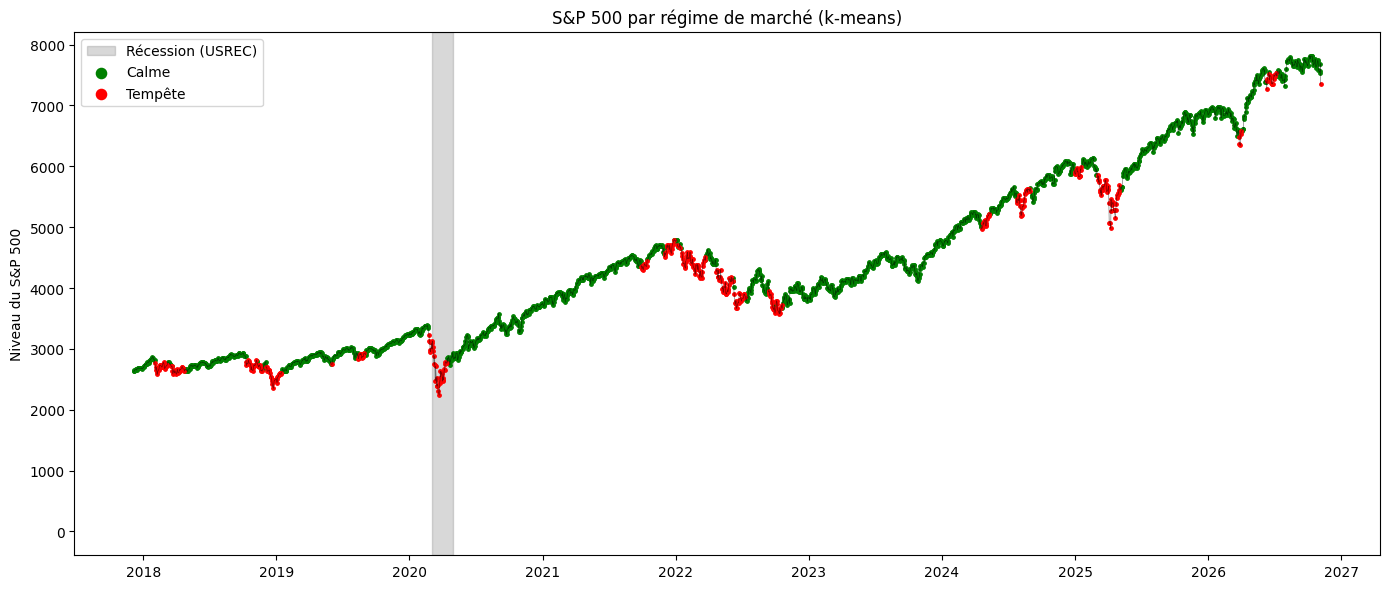

In [8]:
couleurs_par_K = {
    2: ["green", "red"],
    3: ["green", "orange", "red"],
    4: ["green", "gold", "orange", "red"],
    5: ["green", "yellowgreen", "gold", "orange", "red"],
}
couleurs = dict(zip(noms, couleurs_par_K[K]))

fig, ax = plt.subplots(figsize=(14, 6))

# Bande grise pour les récessions
ax.fill_between(dfc.index, 0, 1, where=(dfc["recession"] == 1),
                transform=ax.get_xaxis_transform(),
                color="grey", alpha=0.3, label="Récession (USREC)")

# Courbe fine + points colorés par régime
ax.plot(dfc.index, dfc["SP500"], color="black", linewidth=0.5, alpha=0.5)
for nom in noms:
    sous = dfc[dfc["regime_km"] == nom]
    ax.scatter(sous.index, sous["SP500"], s=6, color=couleurs[nom], label=nom)

ax.set_title("S&P 500 par régime de marché (k-means)")
ax.set_ylabel("Niveau du S&P 500")
ax.legend(markerscale=3)
plt.tight_layout()
plt.savefig("regimes_sp500.png", dpi=150)
plt.show()